<a href="https://colab.research.google.com/github/stephania99c/Proyecto-Machine-Learning/blob/main/Proyecto_ML_Analisis_de_Sentimientos_TRANSFER_LEARNING.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyecto Final Machine Learning - Análisis de Sentimientos

**Estudiante:** Stephanía Cárdenas


## 1. Introducción



Las reseñas en línea se han convertido en una de las principales fuentes de información para los consumidores al elegir un restaurante, un servicio o un comercio, y para las empresas al evaluar la percepción de sus clientes. Sin embargo, el volumen de opiniones que se publica en plataformas como Yelp hace inviable leerlas y clasificarlas manualmente. El análisis de sentimientos, el área que estudia la identificación automática de la opinión expresada en un texto [2], [3], permite resumir grandes cantidades de reseñas y detectar a tiempo experiencias negativas, tendencias en la satisfacción de los clientes o aspectos del servicio que requieren atención.

El objetivo de este proyecto es construir un modelo de aprendizaje automático que clasifique reseñas de Yelp como negativas o positivas a partir de su texto. Para representar las reseñas se utiliza transfer learning en su modalidad de extracción de características: un modelo de lenguaje preentrenado, con sus pesos congelados, convierte cada reseña en un vector numérico que resume su significado. Sobre estas representaciones se entrenan y comparan dos clasificadores, la regresión logística y una máquina de vectores de soporte (SVM), siguiendo una metodología que incluye análisis exploratorio de los datos, construcción de pipelines, optimización de hiperparámetros mediante validación cruzada repetida, comparación estadística de ambos modelos y evaluación final en un conjunto de prueba independiente.

Se utiliza el dataset Yelp Review Full [1], construido a partir del Yelp Dataset Challenge 2015 y ampliamente empleado como referencia en clasificación de texto. Contiene 650.000 reseñas de entrenamiento y 50.000 de prueba, con el mismo número de reseñas para cada nivel de calificación (1 a 5 estrellas), un balance que proviene del diseño del dataset. El problema se plantea como una clasificación binaria: las reseñas de 1 y 2 estrellas se consideran negativas y las de 4 y 5 estrellas, positivas. Las reseñas de 3 estrellas se excluyen porque, como se muestra en el análisis exploratorio, suelen combinar comentarios positivos y negativos, lo que dificulta asignarles una polaridad clara.

Por restricciones de tiempo, y dado que la metodología exige entrenar los modelos numerosas veces, se trabaja con una submuestra aleatoria y balanceada de 10.000 reseñas de entrenamiento y 2.000 de prueba. La curva de aprendizaje presentada en la sección 5.5 permite evaluar si este tamaño de muestra es suficiente.

## 2. Preparación del entorno y carga de datos

### 2.1 Librerías y semilla

In [1]:
# pandas[4]: librería para manejar tablas (DataFrames). La usaremos para
# cargar, filtrar y muestrear las reseñas.
import pandas as pd

# numpy: librería de cálculo numérico. La necesitaremos para operaciones
# con arreglos (por ejemplo, en la comparación estadística y en t-SNE).
import numpy as np

# Semilla aleatoria: un número fijo que usaremos en TODO lo que sea
# aleatorio (muestreo, división en folds, modelos). Así, cada vez que
# alguien corra la notebook obtendrá exactamente los mismos resultados.
SEED = 22

### 2.2 Carga del dataset

In [2]:
# Fuente: Yelp Review Full (Zhang, Zhao y LeCun, 2015), alojado en
# Hugging Face[5]. El código de carga se tomó de la sección
# "Use this dataset" de la página del dataset.

# Diccionario con la ruta de cada parte (split) del dataset dentro del
# repositorio de Hugging Face. 'train' = entrenamiento, 'test' = prueba.
splits = {
    'train': 'yelp_review_full/train-00000-of-00001.parquet',
    'test':  'yelp_review_full/test-00000-of-00001.parquet'
}

# Leemos SOLO la parte de entrenamiento. El prefijo "hf://" le indica a
# pandas que el archivo está en Hugging Face (Colab ya trae instalada la
# librería que lo permite). El formato parquet es comprimido y rápido.
df = pd.read_parquet("hf://datasets/Yelp/yelp_review_full/" + splits["train"])

### 2.3 Inspección inicial

In [3]:
# .shape devuelve (número de filas, número de columnas).
print("Dimensiones:", df.shape)

# .head() muestra las primeras 5 filas para ver cómo lucen los datos.
df.head()

Dimensiones: (650000, 2)


,label,text
0,4,dr. goldberg offers everything i look for in a...
1,1,"Unfortunately, the frustration of being Dr. Go..."
2,3,Been going to Dr. Goldberg for over 10 years. ...
3,3,Got a letter in the mail last week that said D...
4,0,I don't know what Dr. Goldberg was like before...


## 3. Análisis exploratorio de datos (EDA)

### 3.1 Calidad de los datos

In [4]:
# Contamos los valores vacíos (nulos) en cada columna.
print("Valores nulos por columna:")
print(df.isnull().sum())

# Contamos cuántas reseñas tienen exactamente el mismo texto que otra.
print("\nReseñas duplicadas:", df.duplicated(subset="text").sum())

# Elegimos 3 reseñas al azar (siempre las mismas gracias a SEED)
# y las imprimimos completas para leerlas.
ejemplos = df.sample(n=3, random_state=SEED)

# Recorremos las 3 reseñas una por una.
for indice, fila in ejemplos.iterrows():
    # Sumamos 1 a la etiqueta para mostrar las estrellas reales (1 a 5).
    print("\n" + "=" * 60)
    print("Estrellas:", fila["label"] + 1)
    print(fila["text"])

Valores nulos por columna:
label    0
text     0
dtype: int64

Reseñas duplicadas: 0

Estrellas: 2
Its a 24hour joint it does the job it feeds your tummy -Meh. I've experienced much better food. The place is run down it def. needs a make over. The tacos are my favorite there I give them a 4/5. other than the fish tacos i feel as though the food is bland and the salsa is waterie just a pathetic excuse for Mexican food... sad day for Mexican food in Arizona!

Estrellas: 2
I'm being nice with the 2 stars. This is STRICTLY for the Sangria. It taste just like they make it in Spain! I really thought this place would be great w/ the reviews and all, however, me and the bf left extremely disappointed. As a matter if fact, we left hungry :( The order: Scallops $12, two small piece for the cost, and they were spoiled! The smell of the is still lingering in my nostrils. I can't even describe the odor with out being graphic about unwashed female parts. Gross. Patas Bravas- these were meh. Tasted m

El conjunto de entrenamiento contiene 650.000 reseñas y no presenta valores nulos en ninguna de sus dos columnas (label y text). Tampoco se encontraron reseñas con texto duplicado. Por lo tanto, no es necesario eliminar registros.



### 3.2 Caracteres de formato
Al leer algunas reseñas se encontró una particularidad: los saltos de línea se guardaron como la secuencia literal `\n` y las comillas internas aparecen precedidas por `\"`. Ninguno aporta información sobre el sentimiento. Veamos qué tan seguido pasa esto en las reseñas.

In [5]:
# En Python, dentro de un texto, la barra invertida se escribe doble ("\\")
# para que se interprete como una barra literal.
# Por eso "\\n" busca los dos caracteres: barra + n.
# regex=False indica que buscamos el texto tal cual, no un patrón especial.
tiene_salto = df["text"].str.contains("\\n", regex=False)

# Igual para la comilla escapada: barra + comilla.
tiene_comilla = df["text"].str.contains('\\"', regex=False)

# .sum() cuenta los True (reseñas que sí lo contienen).
# .mean() da la proporción; la multiplicamos por 100 para tener porcentaje.
print("Reseñas con '\\n':", tiene_salto.sum(),
      f"({tiene_salto.mean() * 100:.1f} %)")
print('Reseñas con \'\\"\':', tiene_comilla.sum(),
      f"({tiene_comilla.mean() * 100:.1f} %)")

Reseñas con '\n': 325654 (50.1 %)
Reseñas con '\"': 116943 (18.0 %)


Al cuantificarlos, el 50,1 % de las reseñas (325.654) contiene \n y el 18,0 % (116.943) contiene \".

Solo `\n` afecta al modelo: al separar el texto en palabras, la letra “n” queda unida a la palabra siguiente (por ejemplo, “nthe”), lo que genera términos falsos. Por ello, `\n` se reemplazará por un espacio. Los `\"` no requieren tratamiento, porque tanto la barra como la comilla actúan como separadores.

### 3.3 Limpieza de saltos de línea

In [6]:
# Reemplazamos la secuencia literal "\n" (barra + n) por un espacio.
# Recordatorio: en Python la barra se escribe doble ("\\n") para que
# se interprete como una barra literal y no como un salto de línea.
# regex=False indica que buscamos el texto tal cual.
df["text"] = df["text"].str.replace("\\n", " ", regex=False)

# Verificamos: volvemos a contar cuántas reseñas contienen "\n".
# Si la limpieza funcionó, el resultado debe ser 0.
quedan = df["text"].str.contains("\\n", regex=False).sum()
print("Reseñas que aún contienen '\\n':", quedan)

Reseñas que aún contienen '\n': 0


### 3.4 Distribución de estrellas

Reseñas por número de estrellas:
label
1    130000
2    130000
3    130000
4    130000
5    130000
Name: count, dtype: int64


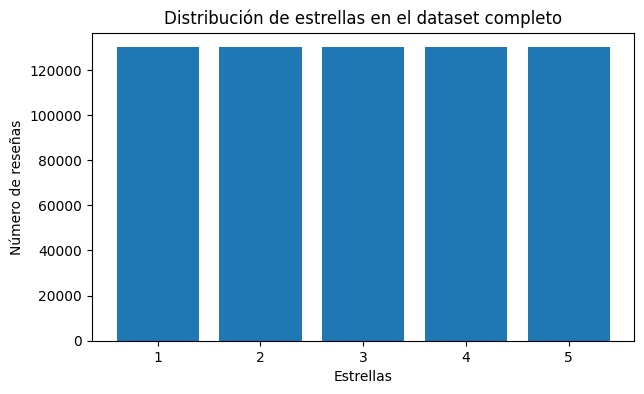

In [7]:
import matplotlib.pyplot as plt

# Contamos cuántas reseñas hay por cada etiqueta (0 a 4).
# sort_index() las ordena de menor a mayor etiqueta.
conteo_estrellas = df["label"].value_counts().sort_index()

# Sumamos 1 al índice para mostrar las estrellas reales (1 a 5)
# en lugar de las etiquetas del dataset (0 a 4).
conteo_estrellas.index = conteo_estrellas.index + 1

# Imprimimos la tabla de conteos.
print("Reseñas por número de estrellas:")
print(conteo_estrellas)

# Gráfico de barras[6]: una barra por número de estrellas
plt.figure(figsize=(7, 4))
plt.bar(conteo_estrellas.index, conteo_estrellas.values)
plt.title("Distribución de estrellas en el dataset completo")
plt.xlabel("Estrellas")
plt.ylabel("Número de reseñas")
plt.show()

El conjunto de entrenamiento contiene exactamente 130.000 reseñas por cada nivel de estrellas (1 a 5). Este balance es artificial: proviene del diseño del dataset, en el que los autores seleccionaron la misma cantidad de reseñas por categoría.

### 3.5 Reseñas de 3 estrellas

In [8]:
# Filtramos solo las reseñas con label == 2 (3 estrellas)
# y elegimos 3 al azar (siempre las mismas gracias a SEED).
ejemplos_3 = df[df["label"] == 2].sample(n=3, random_state=SEED)

# Recorremos las 3 reseñas y las imprimimos completas.
for indice, fila in ejemplos_3.iterrows():
    print("\n" + "=" * 60)
    print(fila["text"])


While I am a fan of the zoo, I'm not a fan of how expensive it has gotten! It is now $20/adult and $10/child from 3-12 years old. This does NOT include the stingray exhibit, carousel, or safari train which are extra. There is a \"premium\" admission which is $23/adult and $13/child which isn't advertised on the website but does include the stingrays, carousel, or safari train. Even with the premium pricing, the camel ride, giraffe encounter, are all additional charges. The food is way over priced.   That having been said, the zoo itself is beautiful. It's very clean with friendly staff and nice, broad based exhibits. The petting zoo is very nicely done and it's always a good visit. Just be prepared to spend a pretty penny on a visit to the Phoenix Zoo.   So as much as I'd like to give it more stars, the Phoenix Zoo is pricing itself out of the market with the nickel diming that it's doing to its guests.

The food and the service was fantastic.  My grip is about the margaritas.  They w

Al leer una muestra aleatoria de reseñas con 3 estrellas se observa que combinan comentarios positivos y negativos en un mismo texto. Esta ambigüedad dificulta asignarles una polaridad clara. Por ello, se excluyen del problema, que se plantea como una clasificación binaria entre reseñas negativas (1–2 estrellas) y positivas (4–5 estrellas). Como limitación, el modelo no aprenderá a reconocer reseñas neutras.

### 3.6 Definición del problema y submuestra

In [9]:
# 1. Filtramos: eliminamos las reseñas de 3 estrellas (label == 2).
# .copy() crea una tabla nueva e independiente, así evitamos
# advertencias de pandas al modificarla.
df_bin = df[df["label"] != 2].copy()

# 2. Recodificamos: creamos la columna 'sentimiento'.
# (df_bin["label"] >= 3) da True para 4 y 5 estrellas y False para 1 y 2.
# .astype(int) convierte True -> 1 (positivo) y False -> 0 (negativo).
df_bin["sentimiento"] = (df_bin["label"] >= 3).astype(int)

# 3. Muestreamos: agrupamos por clase y de cada grupo tomamos 5.000
# reseñas al azar. random_state=SEED garantiza que siempre salgan las mismas.
df_muestra = df_bin.groupby("sentimiento").sample(n=5000, random_state=SEED)

# 4. Mezclamos las filas (frac=1 = el 100 % en orden aleatorio) para que
# no queden primero todas las negativas y luego todas las positivas.
# reset_index(drop=True) renumera las filas de 0 a 9.999.
df_muestra = df_muestra.sample(frac=1, random_state=SEED).reset_index(drop=True)

# Verificamos el resultado.
print("Filas después de quitar 3 estrellas:", df_bin.shape[0])
print("Dimensiones de la submuestra:", df_muestra.shape)
print("\nReseñas por clase (0 = negativo, 1 = positivo):")
print(df_muestra["sentimiento"].value_counts())

Filas después de quitar 3 estrellas: 520000
Dimensiones de la submuestra: (10000, 3)

Reseñas por clase (0 = negativo, 1 = positivo):
sentimiento
0    5000
1    5000
Name: count, dtype: int64


Tras excluir las reseñas de 3 estrellas quedan 520.000 reseñas. Se definió la variable objetivo sentimiento: 0 (negativo) para reseñas de 1 y 2 estrellas, y 1 (positivo) para reseñas de 4 y 5 estrellas. Por limitaciones de tiempo se extrajo una submuestra aleatoria y balanceada de 10.000 reseñas (5.000 por clase), usando una semilla fija para garantizar la reproducibilidad. Con clases balanceadas, un clasificador trivial que siempre prediga la misma clase obtendría un 50 % de accuracy; este valor constituye la línea base que los modelos deben superar.

### 3.7 Longitud de las reseñas por clase

Veamos cuántas palabras tiene cada reseña y comparamos las dos clases. Será que las reseñas negativas tienden a ser más largas o más cortas que las positivas. Si hubiera una diferencia, la longitud por sí sola ya daría una pista sobre el sentimiento.

              count      mean         std  min   25%    50%    75%     max
sentimiento                                                               
0            5000.0  152.3538  135.940991  1.0  61.0  112.0  202.0  1013.0
1            5000.0  112.4018  103.254905  1.0  44.0   83.0  147.0   873.0


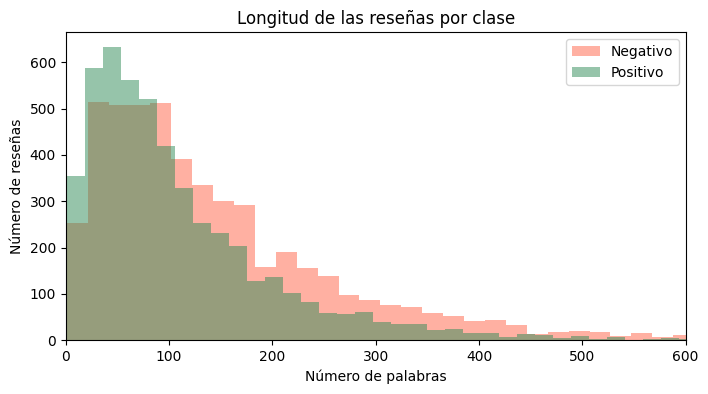

In [10]:
# Contamos las palabras de cada reseña: .str.split() separa el texto
# por espacios y .str.len() cuenta cuántas piezas resultan.
df_muestra["n_palabras"] = df_muestra["text"].str.split().str.len()

# Estadísticas descriptivas de la longitud, separadas por clase:
# promedio (mean), desviación estándar (std), mínimo, cuartiles y máximo.
print(df_muestra.groupby("sentimiento")["n_palabras"].describe())

# Histograma de la longitud para cada clase, superpuestos.
# alpha=0.5 los hace semitransparentes para ver ambos a la vez.
plt.figure(figsize=(8, 4))
plt.hist(df_muestra[df_muestra["sentimiento"] == 0]["n_palabras"],
         bins=50, alpha=0.5, label="Negativo", color="tomato")
plt.hist(df_muestra[df_muestra["sentimiento"] == 1]["n_palabras"],
         bins=50, alpha=0.5, label="Positivo", color="seagreen")

# Limitamos el eje x a 600 palabras: hay pocas reseñas muy largas
# y, si no lo hacemos, el gráfico queda aplastado a la izquierda.
plt.xlim(0, 600)
plt.title("Longitud de las reseñas por clase")
plt.xlabel("Número de palabras")
plt.ylabel("Número de reseñas")
plt.legend()
plt.show()

Las reseñas negativas tienden a ser más extensas que las positivas: su mediana es de 112 palabras, frente a 83 en las positivas, y el 75 % de ellas tiene menos de 202 palabras, frente a 147 en las positivas. En ambas clases la distribución presenta asimetría positiva (el promedio supera a la mediana: 152,4 vs. 112 en negativas y 112,4 vs. 83 en positivas), debido a un pequeño número de reseñas muy largas (máximos de 1.013 y 873 palabras). Por ello, la mediana resume mejor la longitud típica. Aunque existe esta diferencia, las distribuciones se superponen en gran medida, por lo que la longitud por sí sola no sería suficiente para distinguir el sentimiento.

### 3.8 Palabras más frecuentes por clase

Contamos cuántas veces aparece cada palabra en las reseñas negativas y en las positivas, por separado, y graficamos las 15 más frecuentes de cada clase. Usamos CountVectorizer de sklearn, que convierte los textos en conteos de palabras. Le pedimos que elimine las stop words: palabras muy comunes que no expresan sentimiento (the, and, is, it…).

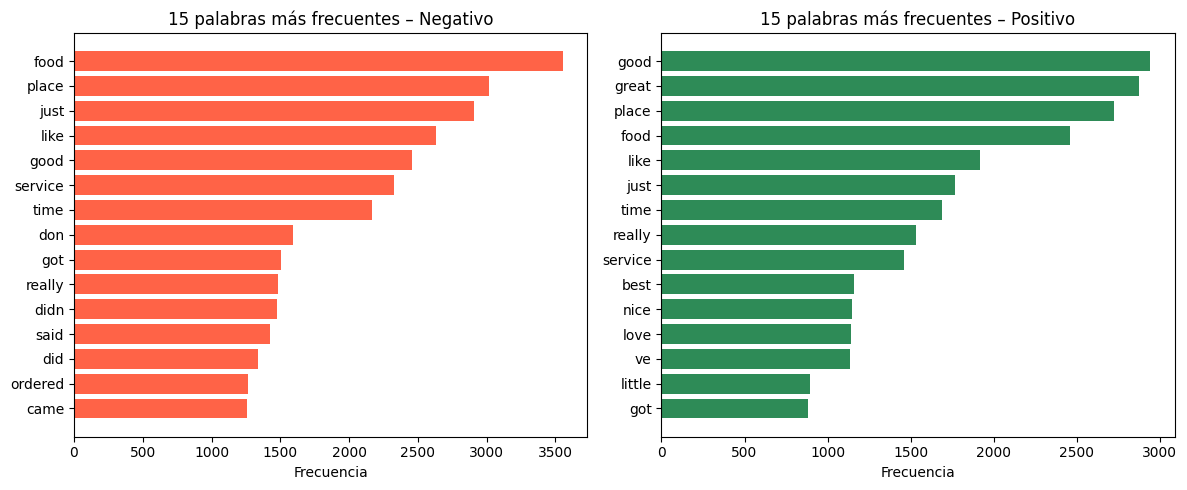

In [11]:
from sklearn.feature_extraction.text import CountVectorizer

def palabras_frecuentes(textos, n=15):
    """Devuelve las n palabras más frecuentes de un conjunto de textos."""
    # CountVectorizer [7]cuenta cuántas veces aparece cada palabra.
    # stop_words="english" elimina palabras comunes sin sentimiento
    # (the, and, is...) que de otro modo dominarían el conteo.
    vectorizador = CountVectorizer(stop_words="english")

    # fit_transform aprende el vocabulario y genera una matriz:
    # una fila por reseña, una columna por palabra, y en cada celda
    # cuántas veces aparece esa palabra en esa reseña.
    conteos = vectorizador.fit_transform(textos)

    # Sumamos cada columna para obtener el total de apariciones
    # de cada palabra en todas las reseñas. .ravel() lo deja como lista plana.
    totales = np.asarray(conteos.sum(axis=0)).ravel()

    # Armamos una serie (palabra -> frecuencia) y tomamos las n mayores.
    serie = pd.Series(totales, index=vectorizador.get_feature_names_out())
    return serie.sort_values(ascending=False).head(n)

# Aplicamos la función a cada clase por separado.
top_neg = palabras_frecuentes(df_muestra[df_muestra["sentimiento"] == 0]["text"])
top_pos = palabras_frecuentes(df_muestra[df_muestra["sentimiento"] == 1]["text"])

# Dos gráficos de barras horizontales lado a lado.
# [::-1] invierte el orden para que la palabra más frecuente quede arriba.
fig, ejes = plt.subplots(1, 2, figsize=(12, 5))
ejes[0].barh(top_neg.index[::-1], top_neg.values[::-1], color="tomato")
ejes[0].set_title("15 palabras más frecuentes – Negativo")
ejes[0].set_xlabel("Frecuencia")
ejes[1].barh(top_pos.index[::-1], top_pos.values[::-1], color="seagreen")
ejes[1].set_title("15 palabras más frecuentes – Positivo")
ejes[1].set_xlabel("Frecuencia")
plt.tight_layout()
plt.show()

Tras eliminar las stop words, varias de las palabras más frecuentes son comunes a ambas clases (food, place, service, time, like, just, really, got) y reflejan el tema de las reseñas más que su sentimiento. Las reseñas positivas incluyen términos con polaridad explícita (great, best, nice, love). En las negativas destacan, en cambio, negaciones (don, didn, provenientes de contracciones como don’t y didn’t) y verbos narrativos en pasado (said, did, ordered, came), lo que sugiere que estas reseñas tienden a relatar la experiencia, en línea con su mayor longitud. La palabra good aparece con alta frecuencia también en reseñas negativas, posiblemente en construcciones negadas (not good), lo que evidencia una limitación del conteo de palabras individuales.

### 3.9 Nube de palabras por clase

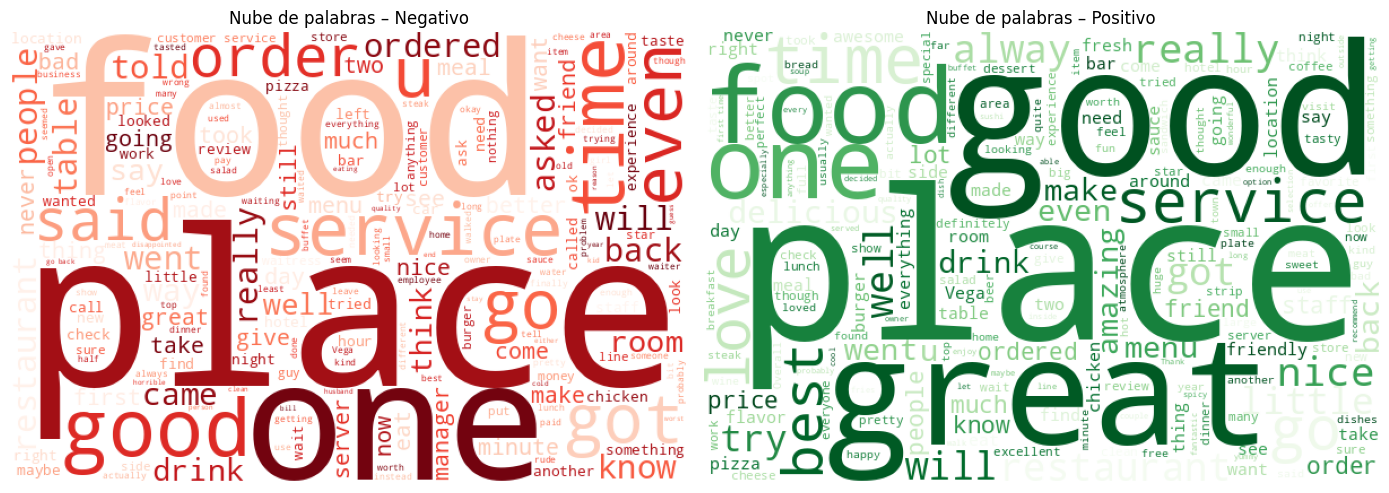

In [12]:
from wordcloud import WordCloud, STOPWORDS

# Juntamos todas las reseñas de cada clase en un solo texto largo.
texto_neg = " ".join(df_muestra[df_muestra["sentimiento"] == 0]["text"])
texto_pos = " ".join(df_muestra[df_muestra["sentimiento"] == 1]["text"])

# WordCloud dibuja cada palabra con un tamaño proporcional a su frecuencia.
# stopwords=STOPWORDS quita palabras comunes sin sentimiento (the, and, is...).
nube_neg = WordCloud(width=600, height=400, background_color="white",
                     stopwords=STOPWORDS, colormap="Reds", random_state=SEED).generate(texto_neg)
nube_pos = WordCloud(width=600, height=400, background_color="white",
                     stopwords=STOPWORDS, colormap="Greens", random_state=SEED).generate(texto_pos)

# Mostramos las dos nubes lado a lado.
fig, ejes = plt.subplots(1, 2, figsize=(14, 5))
ejes[0].imshow(nube_neg)
ejes[0].set_title("Nube de palabras – Negativo")
ejes[0].axis("off")
ejes[1].imshow(nube_pos)
ejes[1].set_title("Nube de palabras – Positivo")
ejes[1].axis("off")
plt.tight_layout()
plt.show()

Las nubes de palabras confirman lo observado en la sección 3.8. En ambas clases dominan términos del tema de las reseñas (place, food, service, one, time). En las positivas destacan palabras de polaridad explícita como great, good, best, love, delicious y amazing. En las negativas predominan verbos que relatan la experiencia (said, ordered, told, asked, came) y aparecen términos como manager y minute, asociados a quejas sobre el servicio y la espera. Good también aparece en las reseñas negativas, posiblemente en construcciones negadas.

### 3.10 Resumen del EDA

1. ¿La data está balanceada? Sí. El dataset completo tiene 130.000 reseñas por estrella, un balance artificial que viene del diseño del dataset, y la submuestra tiene 5.000 reseñas por clase.
2. ¿Está normalizada? Los datos originales son texto, no variables numéricas, así que la normalización no aplica en esa etapa. Las características numéricas (los embeddings) se estandarizan a media 0 y desviación estándar 1 dentro del pipeline, con StandardScaler.
3. ¿Hay estacionalidad? No aplica: no es una serie de tiempo y el dataset no incluye fechas.
4. ¿Se necesitan transformaciones no lineales por asimetría? La longitud de las reseñas tiene asimetría positiva (el promedio supera a la mediana en ambas clases). Sin embargo, la longitud no se usa como característica del modelo, así que no se requiere transformarla.
5. Dominio texto: se presentan las palabras más frecuentes por clase (sección 3.8) y una nube de palabras (sección 3.9).

## 4. Preparación del conjunto de prueba

El dataset Yelp Review Full incluye una partición de prueba oficial de 50.000 reseñas, independiente de las 650.000 de entrenamiento. Se utilizará esta partición para evaluar el modelo final con datos no vistos durante el entrenamiento.

Al conjunto de prueba se le aplican las mismas reglas de preparación definidas a partir del EDA del entrenamiento:

Reemplazo de la secuencia \n por un espacio.
Exclusión de las reseñas de 3 estrellas.
Creación de la variable binaria sentimiento (0 = negativo, 1 = positivo).
Extracción de una muestra aleatoria y balanceada de 2.000 reseñas (1.000 por clase).

Estas transformaciones son reglas fijas, que no aprenden de los datos, por lo que aplicarlas no aporta información sobre el conjunto de prueba.

El conjunto de prueba no se explora ni se utiliza para tomar decisiones de modelado. Solo se usa una vez, en la evaluación final.

In [13]:
# 1. Cargamos la parte 'test' del dataset (50.000 reseñas).
# Usamos el mismo diccionario 'splits' de la celda de carga.
df_test = pd.read_parquet("hf://datasets/Yelp/yelp_review_full/" + splits["test"])
print("Test oficial completo:", df_test.shape)

# 2. Aplicamos la MISMA limpieza que al entrenamiento: "\n" -> espacio.
df_test["text"] = df_test["text"].str.replace("\\n", " ", regex=False)

# 3. Quitamos las reseñas de 3 estrellas (label == 2).
df_test_bin = df_test[df_test["label"] != 2].copy()

# 4. Creamos la misma etiqueta binaria: 1 = positivo (4-5), 0 = negativo (1-2).
df_test_bin["sentimiento"] = (df_test_bin["label"] >= 3).astype(int)

# 5. Muestra balanceada: 1.000 reseñas por clase (2.000 en total).
df_test_muestra = df_test_bin.groupby("sentimiento").sample(n=1000, random_state=SEED)

# 6. Mezclamos las filas y renumeramos.
df_test_muestra = df_test_muestra.sample(frac=1, random_state=SEED).reset_index(drop=True)

# 7. Definimos X (textos) e y (etiquetas) para entrenamiento y prueba.
X_train = df_muestra["text"]
y_train = df_muestra["sentimiento"]
X_test = df_test_muestra["text"]
y_test = df_test_muestra["sentimiento"]

# Verificamos tamaños y balance de clases.
print("\nEntrenamiento:", X_train.shape[0], "reseñas")
print(y_train.value_counts())
print("\nPrueba:", X_test.shape[0], "reseñas")
print(y_test.value_counts())

Test oficial completo: (50000, 2)

Entrenamiento: 10000 reseñas
sentimiento
0    5000
1    5000
Name: count, dtype: int64

Prueba: 2000 reseñas
sentimiento
1    1000
0    1000
Name: count, dtype: int64


## 5. Modelado

### 5.1 Validación cruzada repetida y línea base

In [14]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
from sklearn.dummy import DummyClassifier

# Definimos la validación cruzada que usaremos en TODO el proyecto:
# n_splits=5   -> 5 folds
# n_repeats=2  -> se repite 2 veces con distinta mezcla (2 x 5 = 10 puntajes)
# random_state -> los folds son siempre los mismos
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=SEED)

# Modelo "tonto": siempre predice la clase más frecuente.
# No usa el texto, pero sklearn exige pasarle X igual.
dummy = DummyClassifier(strategy="most_frequent")

# cross_val_score entrena y evalúa el modelo en cada uno de los 10 folds
# y devuelve los 10 valores de accuracy.
scores_dummy = cross_val_score(dummy, X_train, y_train, cv=cv, scoring="accuracy")

# Mostramos los 10 puntajes, su promedio y su desviación estándar.
print("Accuracy en cada fold:", scores_dummy.round(3))
print(f"Accuracy promedio: {scores_dummy.mean():.3f} ± {scores_dummy.std():.3f}")

Accuracy en cada fold: [0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5]
Accuracy promedio: 0.500 ± 0.000


Línea base. Un clasificador trivial que siempre predice la clase más frecuente obtiene una accuracy de 0,500 ± 0,000 en la validación cruzada repetida (2 repeticiones × 5 folds). La desviación es nula porque cada fold estratificado contiene exactamente la mitad de reseñas de cada clase. Este valor es el piso que los modelos propuestos deben superar.

### 5.2 Extracción de características mediante transfer learning

Para representar las reseñas se utiliza transfer learning mediante extracción de características: un modelo de lenguaje preentrenado, con sus pesos congelados, transforma cada reseña en un vector numérico (embedding) que resume su significado. Se emplea el modelo all-MiniLM-L6-v2[11], derivado de la arquitectura BERT [8] y entrenado para generar representaciones de oraciones[9],[10], que produce vectores de 384 dimensiones. Estos embeddings constituyen las características de entrada de los clasificadores. Dado que se utiliza transfer learning sobre texto, se omite la etapa de selección de características, según lo permitido por los lineamientos del proyecto.

In [15]:
import torch
from sentence_transformers import SentenceTransformer

# Verificamos que la GPU esté activa (debe imprimir True).
print("GPU disponible:", torch.cuda.is_available())

# Cargamos el modelo preentrenado. Sus pesos NO se modifican: solo lo usamos
# para transformar texto en vectores (transfer learning, feature extraction).
modelo_emb = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")

# Transformamos cada reseña en un vector de 384 números.
# .tolist() convierte la columna de pandas en una lista de textos.
# batch_size=64: procesa 64 reseñas a la vez (más rápido en GPU).
X_train_emb = modelo_emb.encode(X_train.tolist(), batch_size=64, show_progress_bar=True)
X_test_emb = modelo_emb.encode(X_test.tolist(), batch_size=64, show_progress_bar=True)

# Verificamos las dimensiones: (número de reseñas, 384).
print("Embeddings de entrenamiento:", X_train_emb.shape)
print("Embeddings de prueba:", X_test_emb.shape)

GPU disponible: True


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/157 [00:00<?, ?it/s]

Batches:   0%|          | 0/32 [00:00<?, ?it/s]

Embeddings de entrenamiento: (10000, 384)
Embeddings de prueba: (2000, 384)


Cada reseña quedó representada por un vector de 384 dimensiones: se obtuvieron 10.000 embeddings de entrenamiento y 2.000 de prueba. El conjunto de prueba se transformó con el mismo modelo congelado, sin que este aprenda de sus datos.

Se consideró también la representación TF-IDF (bolsa de palabras), mencionada como alternativa en los lineamientos del proyecto. Se optó por transfer learning porque los embeddings capturan el significado y el contexto de las palabras, mientras que TF-IDF solo cuenta su frecuencia e ignora su orden.

### 5.3 Pipeline: escalado y regresión logística

Los embeddings se obtienen una sola vez, fuera del pipeline, ya que el modelo preentrenado tiene sus pesos congelados y no aprende de los datos, por lo que no existe riesgo de fuga de información. El pipeline incluye un escalado estándar (media 0 y desviación estándar 1), necesario porque la regularización de la regresión logística es sensible a la escala de las características. El escalado se incluye dentro del pipeline porque sus parámetros se estiman a partir de los datos y deben calcularse únicamente con el conjunto de entrenamiento de cada fold.

In [16]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Pipeline: cada paso tiene un nombre (texto) y un objeto.
pipe_lr = Pipeline([
    # Paso 1: escala cada una de las 384 características a media 0 y
    # desviación estándar 1. Se ajusta SOLO con el entrenamiento de cada fold.
    ("escalado", StandardScaler()),
    # Paso 2: clasificador. max_iter=1000 le da suficientes iteraciones
    # para converger; random_state fija los resultados.
    ("clf", LogisticRegression(max_iter=1000, random_state=SEED))
])

# Evaluamos con la misma validación cruzada de la línea base (2 x 5),
# usando ahora los embeddings como características.
scores_lr = cross_val_score(pipe_lr, X_train_emb, y_train, cv=cv,
                            scoring="accuracy", n_jobs=-1)

print("Accuracy en cada fold:", scores_lr.round(3))
print(f"Accuracy promedio: {scores_lr.mean():.3f} ± {scores_lr.std():.3f}")

Accuracy en cada fold: [0.872 0.888 0.883 0.869 0.862 0.878 0.875 0.88  0.879 0.858]
Accuracy promedio: 0.874 ± 0.009


El pipeline con hiperparámetros por defecto obtiene una accuracy de 0,874 ± 0,009 en la validación cruzada repetida, 37,4 puntos porcentuales por encima de la línea base. Los puntajes por fold oscilan entre 0,858 y 0,888. A continuación se optimiza el parámetro de regularización.

### 5.4 Optimización de hiperparámetros  

Se optimiza el parámetro de regularización C de la regresión logística mediante búsqueda en grilla (GridSearchCV), evaluada con la misma validación cruzada repetida (2 repeticiones × 5 folds). La gráfica muestra el error (1 − accuracy) en entrenamiento y en validación en función de C. Valores pequeños de C implican una regularización fuerte (modelo más simple), y valores grandes, una regularización débil (modelo más complejo).

Mejor C: 0.01
Mejor accuracy promedio: 0.877
        C  error_train  error_val  std_test_score
0   0.001        0.123      0.131           0.009
1   0.010        0.108      0.123           0.009
2   0.100        0.102      0.124           0.008
3   1.000        0.102      0.126           0.009
4  10.000        0.102      0.126           0.008


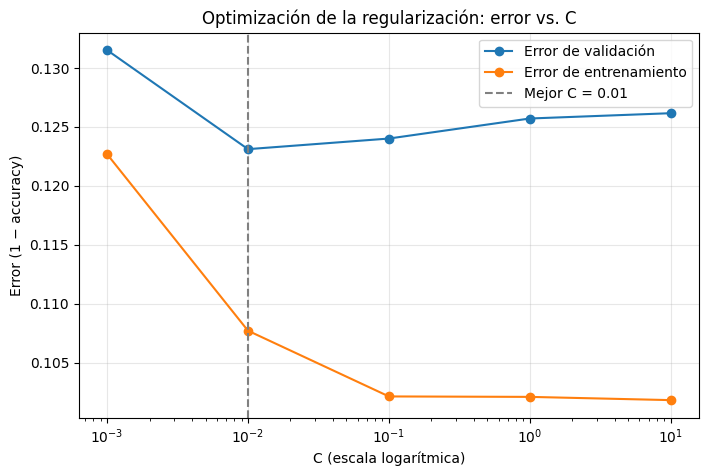

In [17]:
from sklearn.model_selection import GridSearchCV

# Valores de C a probar: pequeños = regularización fuerte; grandes = débil.
grilla = {"clf__C": [0.001, 0.01, 0.1, 1, 10]}

# return_train_score=True: guarda también el desempeño en entrenamiento,
# necesario para graficar la curva de error de entrenamiento.
busqueda = GridSearchCV(pipe_lr, grilla, cv=cv, scoring="accuracy",
                        n_jobs=-1, return_train_score=True)
busqueda.fit(X_train_emb, y_train)

print("Mejor C:", busqueda.best_params_["clf__C"])
print(f"Mejor accuracy promedio: {busqueda.best_score_:.3f}")

# Tabla de resultados: convertimos accuracy en error (1 - accuracy).
resultados = pd.DataFrame(busqueda.cv_results_)
resultados["C"] = resultados["param_clf__C"].astype(float)
resultados["error_train"] = 1 - resultados["mean_train_score"]
resultados["error_val"] = 1 - resultados["mean_test_score"]
print(resultados[["C", "error_train", "error_val", "std_test_score"]]
      .sort_values("C").round(3))

# Gráfica: error vs C, para entrenamiento y validación.
datos = resultados.sort_values("C")
mejor_C = busqueda.best_params_["clf__C"]

plt.figure(figsize=(8, 5))
plt.plot(datos["C"], datos["error_val"], marker="o", label="Error de validación")
plt.plot(datos["C"], datos["error_train"], marker="o", label="Error de entrenamiento")
# Línea vertical punteada en el mejor C.
plt.axvline(mejor_C, color="gray", linestyle="--", label=f"Mejor C = {mejor_C:g}")
plt.xscale("log")
plt.title("Optimización de la regularización: error vs. C")
plt.xlabel("C (escala logarítmica)")
plt.ylabel("Error (1 − accuracy)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

La mejor configuración fue C = 0,01, con una accuracy de 0,877 ± 0,009. Con regularización excesiva (C = 0,001), los dos errores aumentan (subajuste). Con C ≥ 0,1, la brecha entre entrenamiento y validación crece a unos 2,4 puntos (sobreajuste leve). En general, el desempeño es poco sensible a C (0,874–0,877 entre 0,01 y 10), porque los embeddings tienen solo 384 dimensiones frente a 10.000 reseñas.

### 5.5 Curva de aprendizaje  

La curva de aprendizaje muestra el error (1 − accuracy) del mejor modelo (C = 0,01) en entrenamiento y en validación al variar el tamaño del conjunto de entrenamiento. Permite evaluar si el modelo presenta sobreajuste y si un mayor tamaño de muestra mejoraría su desempeño.

   n_entrenamiento  error_train  error_val  std_val
0              800        0.078      0.149    0.007
1             2600        0.098      0.135    0.009
2             4400        0.104      0.131    0.009
3             6200        0.105      0.124    0.009
4             8000        0.108      0.123    0.009


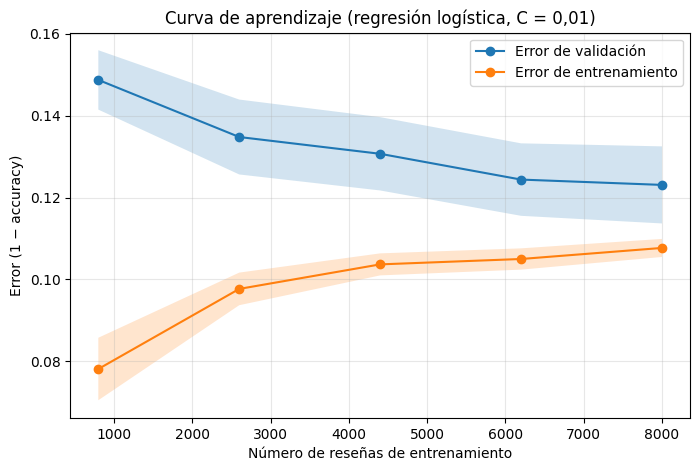

In [18]:
from sklearn.model_selection import learning_curve

# best_estimator_ es el pipeline con el mejor C encontrado.
mejor_modelo = busqueda.best_estimator_

# Entrenamos con 5 tamaños entre el 10 % y el 100 % de los datos de cada fold.
tamanos, scores_train, scores_val = learning_curve(
    mejor_modelo, X_train_emb, y_train,
    train_sizes=np.linspace(0.1, 1.0, 5),
    cv=cv, scoring="accuracy", n_jobs=-1
)

# Convertimos accuracy en error (1 - accuracy) y promediamos sobre los
# 10 folds (axis=1 = columnas).
error_train = 1 - scores_train
error_val = 1 - scores_val
media_train, std_train = error_train.mean(axis=1), error_train.std(axis=1)
media_val, std_val = error_val.mean(axis=1), error_val.std(axis=1)

# Tabla para citar los valores en la interpretación.
print(pd.DataFrame({
    "n_entrenamiento": tamanos,
    "error_train": media_train.round(3),
    "error_val": media_val.round(3),
    "std_val": std_val.round(3)
}))

# Gráfico: error vs tamaño de entrenamiento, con bandas de ± 1 desviación.
plt.figure(figsize=(8, 5))
plt.plot(tamanos, media_val, marker="o", label="Error de validación")
plt.fill_between(tamanos, media_val - std_val, media_val + std_val, alpha=0.2)
plt.plot(tamanos, media_train, marker="o", label="Error de entrenamiento")
plt.fill_between(tamanos, media_train - std_train, media_train + std_train, alpha=0.2)
plt.title("Curva de aprendizaje (regresión logística, C = 0,01)")
plt.xlabel("Número de reseñas de entrenamiento")
plt.ylabel("Error (1 − accuracy)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Al pasar de 800 a 8.000 reseñas, el error de validación baja de 0,149 a 0,123 y la brecha con el entrenamiento se reduce de 7,1 a 1,5 puntos. La curva se aplana al final (solo mejora 0,1 puntos entre 6.200 y 8.000), así que más datos aportarían poco. Ambas curvas convergen cerca de un 11–12 % de error: el límite está en la representación (un modelo preentrenado de propósito general), no en la cantidad de datos.

## 6. Comparación estadística de dos modelos

Se compara la regresión logística con una máquina de vectores de soporte (SVM) [12] con kernel RBF. A diferencia de la regresión logística, que modela la probabilidad de cada clase mediante una frontera lineal, la SVM busca la frontera que maximiza el margen entre clases y, con el kernel RBF, permite fronteras no lineales. Para que la comparación sea justa, la SVM se integra en el mismo pipeline (escalado estándar) y su parámetro de regularización C se optimiza con la misma búsqueda en grilla y validación cruzada repetida.

In [19]:
from sklearn.svm import SVC

# Mismo pipeline: escalado + clasificador, ahora SVM con kernel RBF.
pipe_svm = Pipeline([
    ("escalado", StandardScaler()),
    # kernel="rbf": frontera no lineal. gamma usa su valor por defecto ("scale").
    ("clf", SVC(kernel="rbf", random_state=SEED))
])

# Valores de C a probar (igual que en regresión logística:
# pequeños = regularización fuerte; grandes = débil).
grilla_svm = {"clf__C": [0.1, 1, 10]}

# Misma búsqueda en grilla y misma validación cruzada 'cv'.
busqueda_svm = GridSearchCV(pipe_svm, grilla_svm, cv=cv, scoring="accuracy", n_jobs=-1)
busqueda_svm.fit(X_train_emb, y_train)

print("Mejor C (SVM):", busqueda_svm.best_params_["clf__C"])
print(f"Mejor accuracy promedio (SVM): {busqueda_svm.best_score_:.3f}")

# Tabla de resultados ordenada por C.
resultados_svm = pd.DataFrame(busqueda_svm.cv_results_)
resultados_svm["C"] = resultados_svm["param_clf__C"].astype(float)
print(resultados_svm[["C", "mean_test_score", "std_test_score"]].sort_values("C").round(3))

Mejor C (SVM): 1
Mejor accuracy promedio (SVM): 0.880
      C  mean_test_score  std_test_score
0   0.1            0.857           0.011
1   1.0            0.880           0.010
2  10.0            0.877           0.009


La búsqueda en grilla para la SVM evaluó C = 0,1, 1 y 10. La mejor configuración fue C = 1, con una accuracy promedio de 0,880 ± 0,010, ubicada en el interior de la grilla: con C = 0,1 la accuracy desciende a 0,857 (subajuste por exceso de regularización) y con C = 10 se reduce levemente a 0,877. El desempeño de la mejor SVM es muy similar al de la mejor regresión logística (0,877 ± 0,009).

### 6.2 Prueba de Wilcoxon

Se evalúan los dos modelos optimizados en los mismos 10 folds de la validación cruzada repetida (2 × 5) y se aplica la prueba de rangos con signo de Wilcoxon [13,14] sobre las diferencias pareadas de accuracy. La hipótesis nula establece que no existe diferencia en el desempeño de ambos modelos; se utiliza un nivel de significancia de 0,05. Se eligió esta prueba no paramétrica porque no requiere suponer normalidad en las diferencias.

   Regresión logística  SVM (RBF)  Diferencia (RL - SVM)
0                0.879      0.876                  0.004
1                0.888      0.892                 -0.003
2                0.890      0.888                  0.002
3                0.866      0.878                 -0.012
4                0.868      0.868                 -0.001
5                0.872      0.870                  0.003
6                0.878      0.885                 -0.007
7                0.885      0.890                 -0.004
8                0.882      0.891                 -0.009
9                0.861      0.860                  0.000

Regresión logística: 0.877 ± 0.009
SVM (RBF):           0.880 ± 0.010

Estadístico de Wilcoxon: 14.0
p-valor: 0.1934


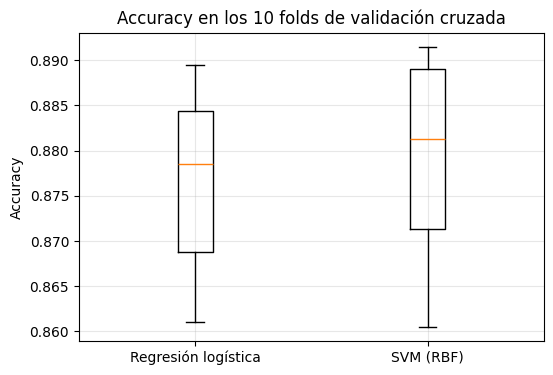

In [20]:
from scipy.stats import wilcoxon

# Los puntajes de cada fold ya se calcularon durante la búsqueda en grilla.
# Los tomamos de cv_results_ para el mejor C de cada modelo, sin volver a
# entrenar. Como ambos usaron la misma 'cv', los folds son los mismos.
n_folds = cv.get_n_splits()                       # 2 x 5 = 10 folds
idx_lr = busqueda.best_index_                     # fila del mejor C (reg. logística)
idx_svm = busqueda_svm.best_index_                # fila del mejor C (SVM)

scores_lr_final = np.array([busqueda.cv_results_[f"split{i}_test_score"][idx_lr]
                            for i in range(n_folds)])
scores_svm_final = np.array([busqueda_svm.cv_results_[f"split{i}_test_score"][idx_svm]
                             for i in range(n_folds)])

# Tabla fold por fold con la diferencia entre ambos modelos.
comparacion = pd.DataFrame({
    "Regresión logística": scores_lr_final,
    "SVM (RBF)": scores_svm_final,
    "Diferencia (RL - SVM)": scores_lr_final - scores_svm_final
})
print(comparacion.round(3))
print(f"\nRegresión logística: {scores_lr_final.mean():.3f} ± {scores_lr_final.std():.3f}")
print(f"SVM (RBF):           {scores_svm_final.mean():.3f} ± {scores_svm_final.std():.3f}")

# Prueba de Wilcoxon sobre las diferencias pareadas.
estadistico, p_valor = wilcoxon(scores_lr_final, scores_svm_final)
print(f"\nEstadístico de Wilcoxon: {estadistico}")
print(f"p-valor: {p_valor:.4f}")

# Diagrama de cajas con los 10 puntajes de cada modelo.
plt.figure(figsize=(6, 4))
plt.boxplot([scores_lr_final, scores_svm_final])
plt.xticks([1, 2], ["Regresión logística", "SVM (RBF)"])
plt.title("Accuracy en los 10 folds de validación cruzada")
plt.ylabel("Accuracy")
plt.grid(True, alpha=0.3)
plt.show()

La SVM obtuvo 0,880 ± 0,010 y la regresión logística 0,877 ± 0,009. La prueba de Wilcoxon dio p = 0,1934 > 0,05, por lo que no se rechaza la hipótesis nula: no hay diferencia significativa entre los modelos, y el diagrama de cajas lo confirma. Por parsimonia, se elige la regresión logística como modelo final: es más simple, más rápida y entrega probabilidades.

## 7. Evaluación final en el conjunto de prueba

El modelo seleccionado (regresión logística con C = 0,01), reentrenado con los embeddings de las 10.000 reseñas de entrenamiento, se evalúa una única vez sobre las 2.000 reseñas del conjunto de prueba oficial. Además de la accuracy, se reportan la precisión, el recall y el F1-score por clase, y la matriz de confusión.

Accuracy en prueba: 0.879

               precision    recall  f1-score   support

    Negativo      0.872     0.890     0.881      1000
    Positivo      0.888     0.869     0.878      1000

    accuracy                          0.879      2000
   macro avg      0.880     0.879     0.879      2000
weighted avg      0.880     0.879     0.879      2000



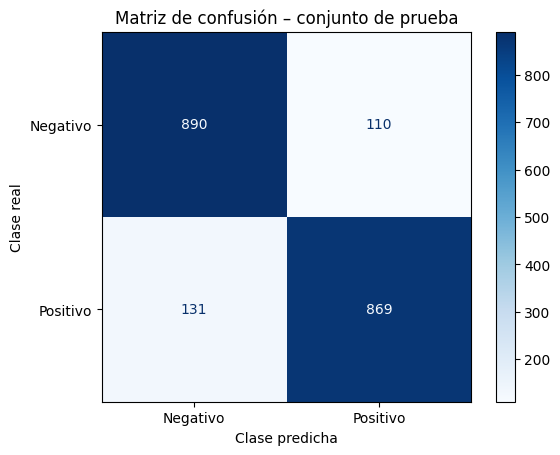

In [21]:
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

# El mejor modelo ya está entrenado con todos los embeddings de entrenamiento
# (GridSearchCV lo reentrena automáticamente al final de la búsqueda).
modelo_final = busqueda.best_estimator_

# Predecimos las etiquetas de las 2.000 reseñas de prueba.
y_pred = modelo_final.predict(X_test_emb)

# Accuracy en el conjunto de prueba.
print(f"Accuracy en prueba: {accuracy_score(y_test, y_pred):.3f}")

# Reporte por clase: precisión, recall y F1-score.
print("\n", classification_report(y_test, y_pred,
                                  target_names=["Negativo", "Positivo"], digits=3))

# Matriz de confusión: filas = clase real, columnas = clase predicha.
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["Negativo", "Positivo"], cmap="Blues"
)
plt.xlabel("Clase predicha")
plt.ylabel("Clase real")
plt.title("Matriz de confusión – conjunto de prueba")
plt.show()

En el conjunto de prueba oficial, el modelo final obtiene una accuracy de 0,879, consistente con la estimada en validación cruzada (0,877). Esto indica que el modelo generaliza adecuadamente a reseñas no vistas y que la validación cruzada proporcionó una estimación confiable de su desempeño. El resultado supera en 37,9 puntos porcentuales a la línea base del 50 %.

La matriz de confusión muestra 110 reseñas negativas clasificadas como positivas y 131 positivas clasificadas como negativas, con un total de 241 errores sobre 2.000 reseñas (12 %). Existe una leve tendencia a clasificar reseñas como negativas, que se refleja en un recall mayor para la clase negativa (0,890) que para la positiva (0,869). No obstante, la diferencia es pequeña y el desempeño es equilibrado entre clases, con F1-scores de 0,881 y 0,878.

### 7.1 Análisis de errores

Para entender las limitaciones del modelo se analizan sus errores en el conjunto de prueba: se calcula la tasa de error según el número de estrellas original de cada reseña y se leen ejemplos de reseñas mal clasificadas de ambos tipos, junto con la probabilidad asignada por el modelo a la clase positiva.

In [22]:
# Tabla con la información de cada reseña de prueba.
analisis = pd.DataFrame({
    "texto": X_test,                              # texto original de la reseña
    "estrellas": df_test_muestra["label"] + 1,    # estrellas reales (1 a 5)
    "real": y_test,
    "predicho": y_pred,
    # predict_proba devuelve [prob. negativo, prob. positivo];
    # [:, 1] toma la probabilidad de que sea positiva.
    "prob_positivo": modelo_final.predict_proba(X_test_emb)[:, 1]
})

# Marcamos con True las reseñas mal clasificadas.
analisis["error"] = analisis["real"] != analisis["predicho"]

# 1. Tasa de error por número de estrellas.
print("Tasa de error según estrellas originales:")
print((analisis.groupby("estrellas")["error"].mean() * 100).round(1).astype(str) + " %")

# 2. Ejemplos de los dos tipos de error.
falsos_pos = analisis[(analisis["real"] == 0) & (analisis["predicho"] == 1)]
falsos_neg = analisis[(analisis["real"] == 1) & (analisis["predicho"] == 0)]

# Mostramos 3 ejemplos al azar de cada tipo.
for titulo, grupo in [("NEGATIVAS clasificadas como POSITIVAS", falsos_pos),
                      ("POSITIVAS clasificadas como NEGATIVAS", falsos_neg)]:
    print("\n" + "#" * 60)
    print(titulo)
    for indice, fila in grupo.sample(n=3, random_state=SEED).iterrows():
        print("\n" + "=" * 60)
        print(f"Estrellas: {fila['estrellas']} | Prob. positivo: {fila['prob_positivo']:.2f}")
        print(fila["texto"])

Tasa de error según estrellas originales:
estrellas
1     4.1 %
2    17.6 %
4    18.4 %
5     8.0 %
Name: error, dtype: object

############################################################
NEGATIVAS clasificadas como POSITIVAS

Estrellas: 2 | Prob. positivo: 0.63
I used to really like the angle club. I used to go twice a week with my friends and fritter away hours trying to get better at snooker. It's got everything you could want in a snooker club - 10 snooker tables, several pool tables, a bar, a darts room and a little lounge/waiting area. Then I stopped going, and I'll tell you why.  Last year I acquired a snooker cue from an aging relative. It was a nice cue but it needed re-tipping. Where best to get that done,  I thought, than the local snooker club I so often visit. So I took the cue in and, sure enough, they could re-tip it no problem. And for \u00a32.50! What service! A couple of weeks later, still with no re-tipped cue my conversation with one of the staff there went somethi

La tasa de error es de 4,1 % en las reseñas de 1 estrella y de 8,0 % en las de 5, pero sube a 17,6 % y 18,4 % en las de 2 y 4 estrellas: las reseñas moderadas, más cercanas a la frontera neutra, son las más difíciles. Los ejemplos mal clasificados muestran opiniones expresadas de forma indirecta (“Not the top on my list”), contrastes entre experiencias pasadas y presentes, elogios moderados construidos con negaciones (“It’s not as greasy as some… so it passes”) y reseñas que mezclan críticas y elogios. Varios errores tienen probabilidades cercanas a 0,5, lo que indica que el modelo detectó la ambigüedad.

## 8. Visualización con t-SNE  

Se utiliza t-SNE [16] para visualizar en dos dimensiones el espacio de características del modelo, formado por los embeddings de 384 dimensiones. Debido al costo computacional de t-SNE, se trabaja con una muestra balanceada de 2.000 reseñas de entrenamiento y se reduce previamente la dimensionalidad a 50 componentes mediante PCA [15]. Cada punto se colorea según su clase real.

Varianza explicada por las 50 componentes: 0.610


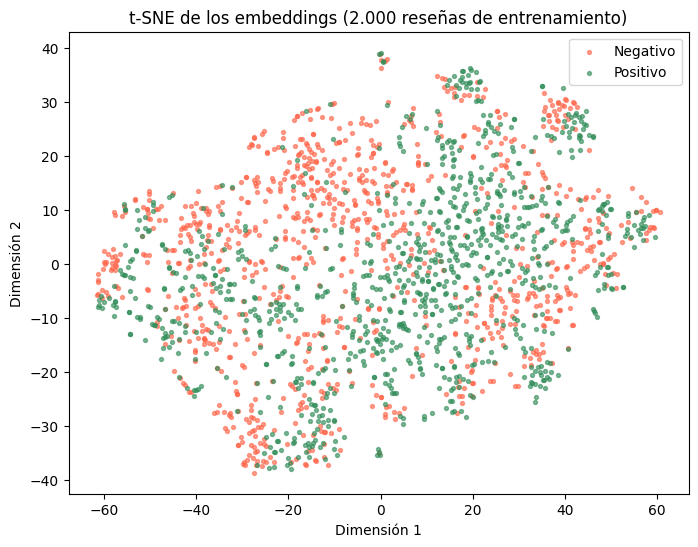

In [23]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# 1. Elegimos 2.000 reseñas de entrenamiento (1.000 por clase).
# Como df_muestra tiene índices de 0 a 9.999 en el mismo orden que
# X_train_emb, los índices sirven para tomar las filas de los embeddings.
indices = df_muestra.groupby("sentimiento").sample(n=1000, random_state=SEED).index
X_sub = X_train_emb[indices]
etiquetas = y_train.loc[indices].values

# 2. PCA: reducimos de 384 a 50 dimensiones.
pca = PCA(n_components=50, random_state=SEED)
X_pca = pca.fit_transform(X_sub)
print(f"Varianza explicada por las 50 componentes: {pca.explained_variance_ratio_.sum():.3f}")

# 3. t-SNE: de 50 a 2 dimensiones.
tsne = TSNE(n_components=2, perplexity=30, random_state=SEED)
X_2d = tsne.fit_transform(X_pca)

# 4. Gráfico: un color por clase.
plt.figure(figsize=(8, 6))
plt.scatter(X_2d[etiquetas == 0, 0], X_2d[etiquetas == 0, 1],
            s=8, alpha=0.6, color="tomato", label="Negativo")
plt.scatter(X_2d[etiquetas == 1, 0], X_2d[etiquetas == 1, 1],
            s=8, alpha=0.6, color="seagreen", label="Positivo")
plt.title("t-SNE de los embeddings (2.000 reseñas de entrenamiento)")
plt.xlabel("Dimensión 1")
plt.ylabel("Dimensión 2")
plt.legend()
plt.show()

Las 50 componentes de PCA explican el 61,0 % de la varianza. Se observan zonas con predominio de cada clase, pero con bastante superposición. Esto no contradice la accuracy del 88 %: t-SNE es no supervisado y agrupa por similitud general de significado, en la que también influye el tema de la reseña, mientras que la regresión logística aprende específicamente qué dimensiones separan las clases.

## 9. Alcance y limitaciones

**Alcance:**

Clasificación binaria del sentimiento de reseñas de Yelp en inglés, con una submuestra balanceada de 10.000 reseñas de entrenamiento y 2.000 de prueba, usando embeddings de un modelo preentrenado y comparando regresión logística y SVM.

**Limitaciones:**
- Se excluyeron las reseñas de 3 estrellas, por lo que el modelo no reconoce opiniones neutras.
- El modelo preentrenado es de propósito general y no se ajustó a este problema (sin fine-tuning); las reseñas largas se truncan.
- Se usó una submuestra de las 520.000 reseñas disponibles, aunque la curva de aprendizaje indica que más datos aportarían poco.
- El balance de clases es artificial y los datos son de 2015, en inglés.
- Se usó la configuración mínima de validación cruzada (2 × 5) y una grilla acotada de hiperparámetros.

## 10. Conclusiones  

1. La regresión logística sobre embeddings alcanzó una accuracy de 0,879 en el conjunto de prueba, consistente con la validación cruzada (0,877) y 37,9 puntos por encima de la línea base. El desempeño es equilibrado entre clases (F1 de 0,881 y 0,878).
2. No hubo diferencia significativa entre la regresión logística y la SVM (Wilcoxon, p = 0,1934). Se eligió la regresión logística por parsimonia; que una frontera no lineal no mejore el resultado sugiere que las clases son casi linealmente separables en el espacio de los embeddings.
3. El desempeño está limitado por la representación, no por la cantidad de datos: la regularización tuvo poco efecto, salvo cuando fue excesiva, y la curva de aprendizaje se estabiliza cerca de un 12 % de error.
4. Los errores se concentran en las reseñas moderadas: la tasa de error es de 17,6 % y 18,4 % en 2 y 4 estrellas, frente a 4,1 % y 8,0 % en 1 y 5 estrellas. Abundan el lenguaje indirecto, las negaciones y las opiniones mixtas.

Trabajo futuro: usar un modelo preentrenado para sentimientos o hacer fine-tuning, incluir las reseñas neutras y repetir la comparación con 10 × 10 folds.

## 11. Referencias  

[1] X. Zhang, J. Zhao y Y. LeCun, “Character-level convolutional networks for text classification,” en Advances in Neural Information Processing Systems 28 (NIPS 2015), 2015, pp. 649–657.

[2] B. Pang y L. Lee, “Opinion mining and sentiment analysis,” Foundations and Trends in Information Retrieval, vol. 2, no. 1–2, pp. 1–135, 2008.

[3] B. Liu, Sentiment Analysis and Opinion Mining. San Rafael, CA, EE. UU.: Morgan & Claypool, 2012.

[4] W. McKinney, “Data structures for statistical computing in Python,” en Proc. 9th Python in Science Conference, 2010, pp. 56–61.

[5] Yelp, “yelp_review_full,” Hugging Face. [En línea]. Disponible: https://huggingface.co/datasets/Yelp/yelp_review_full. Accedido: 15 de octubre de 2026.

[6] J. D. Hunter, “Matplotlib: A 2D graphics environment,” Computing in Science & Engineering, vol. 9, no. 3, pp. 90–95, 2007.

[7] F. Pedregosa et al., “Scikit-learn: Machine learning in Python,” Journal of Machine Learning Research, vol. 12, pp. 2825–2830, 2011.

[8] J. Devlin, M.-W. Chang, K. Lee y K. Toutanova, “BERT: Pre-training of deep bidirectional transformers for language understanding,” en Proc. NAACL-HLT, 2019, pp. 4171–4186.

[9] N. Reimers e I. Gurevych, “Sentence-BERT: Sentence embeddings using Siamese BERT-networks,” en Proc. EMNLP-IJCNLP, 2019, pp. 3982–3992.

[10] W. Wang, F. Wei, L. Dong, H. Bao, N. Yang y M. Zhou, “MiniLM: Deep self-attention distillation for task-agnostic compression of pre-trained transformers,” en Advances in Neural Information Processing Systems 33 (NeurIPS 2020), 2020, pp. 5776–5788.

[11] Sentence Transformers, “all-MiniLM-L6-v2,” Hugging Face. [En línea]. Disponible: https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2. Accedido: 15 de octubre de 2026.

[12] C. Cortes y V. Vapnik, “Support-vector networks,” Machine Learning, vol. 20, no. 3, pp. 273–297, 1995.

[13] F. Wilcoxon, “Individual comparisons by ranking methods,” Biometrics Bulletin, vol. 1, no. 6, pp. 80–83, 1945.

[14] P. Virtanen et al., “SciPy 1.0: Fundamental algorithms for scientific computing in Python,” Nature Methods, vol. 17, pp. 261–272, 2020.

[15] I. T. Jolliffe, Principal Component Analysis, 2.ª ed. Nueva York, NY, EE. UU.: Springer, 2002.

[16] L. van der Maaten y G. Hinton, “Visualizing data using t-SNE,” Journal of Machine Learning Research, vol. 9, pp. 2579–2605, 2008.

## 12. Uso de herramientas de IA

In [24]:
# Uso de inteligencia artificial (Claude, de Anthropic):
#
# "Acompáñame paso a paso a cumplir la rúbrica de mi proyecto de análisis de
# sentimientos con reseñas de Yelp, trabajando con una submuestra. Antes de cada
# parte, explícame el concepto; luego dame el código comentado, sencillo y apegado
# a lo visto en clase, una celda a la vez. Cuando te envíe mis resultados, ayúdame
# a interpretarlos y a redactar los textos usando solo mis números."
#
# Las decisiones del proyecto (dataset, etiqueta binaria, submuestra, uso de
# transfer learning y elección de los modelos) fueron tomadas por la autora.
# Todo el código fue ejecutado, revisado y comprendido por la autora.